# Semana 5 — Programación dinámica, retroceso, módulos y pandas aplicado a Penonomé

Aplica las unidades 32 a 36 del curso: [programación dinámica](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u32-programacion-dinamica.ipynb), [retroceso](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb), [módulos de Python](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb), [Series de pandas](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb) y [DataFrames de pandas](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb).

[Proyecto](../../README.md) | [Anterior](s04-ordenamiento-greedy-divide-y-venceras.ipynb) | [Siguiente](s06-ordenacion-series-temporales.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Qué hace este notebook

Hasta la semana 4 el proyecto leía los CSV con el módulo `csv` y trabajaba con listas y diccionarios (`penonome.carga` y `penonome.modelos`). Desde aquí los datos se cargan con pandas y las funciones nuevas viven en un módulo propio, `penonome.analisis`, que también usa el notebook de la semana 6.

| Sección | Unidad | Datos |
|---|---|---|
| 1. Módulos y paquetes | u34 | paquete `penonome` y fechas del sismo y de los cortes de SINAPROC |
| 2. Series | u35 | población por corregimiento (Censo 2023, tabla 01) |
| 3. DataFrames | u36 | afectaciones del sismo en Coclé (SINAPROC, EDAN) y Censo 2023 (tabla 02) |
| 4. Programación dinámica | u32 | edad y sexo de las personas evaluadas (SINAPROC) y pobreza multidimensional por corregimiento (PNUD, tabla 03) |
| 5. Retroceso | u33 | población por corregimiento (tabla 01) |

Todas las cifras son oficiales (INEC, PNUD, SINAPROC) salvo donde se indica que se trata de un supuesto ilustrativo.

## 1. Módulos y paquetes: `penonome.analisis`

En la [Unidad 34](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb) un módulo es un archivo `.py` que se importa por su nombre sin la extensión, y se usa con la forma `modulo.funcion()`. El proyecto aplica la misma idea a mayor escala: `src/penonome/` es un **paquete**, una carpeta de módulos, y cada semana agrega uno.

| Módulo | Semana | Qué contiene |
|---|---|---|
| `penonome/__init__.py` | todas | las rutas `RAIZ`, `PAQUETE` y `ANALISIS` |
| `penonome/carga.py` | 1 y 2 | lectura de los CSV con el módulo `csv` |
| `penonome/modelos.py` | 2 | las clases `Corregimiento` y `Fuente` |
| `penonome/estructuras.py` y `penonome/busqueda.py` | 3 | pilas, colas, tablas hash y búsquedas |
| `penonome/ordenamiento.py` | 4 | algoritmos de ordenamiento |
| `penonome/analisis.py` | 5 y 6 | pandas, programación dinámica y retroceso |

**Ampliación (no está en el PDF):** el archivo `__init__.py` convierte la carpeta en paquete y se ejecuta la primera vez que se importa `penonome`; por eso las rutas se definen ahí una sola vez y los demás módulos las importan con `from penonome import PAQUETE`. El ambiente de uv instala el paquete en modo editable, así que un cambio en `analisis.py` se ve al reiniciar el kernel sin reinstalar nada.

In [2]:
import sys
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd

import penonome                          # el paquete: ejecuta penonome/__init__.py
import penonome.analisis as an           # la sentencia as de la u34
from penonome.analisis import leer       # la sentencia from de la u34

print("Paquete :", penonome.__name__, "->", penonome.__file__.split("src/")[-1])
print("Módulo  :", an.__name__, "->", an.__file__.split("src/")[-1])
print("Datos   :", penonome.PAQUETE.name, "y", penonome.ANALISIS.name)
print("Funciones públicas de analisis:")
print([nombre for nombre in dir(an) if not nombre.startswith("_") and callable(getattr(an, nombre))])

Paquete : penonome -> penonome/__init__.py
Módulo  : penonome.analisis -> penonome/analisis.py
Datos   : penonome y analisis
Funciones públicas de analisis:
['a_ancho', 'a_largo', 'afectaciones', 'base_larga', 'combinaciones_minimas', 'estilo_eje', 'indice_base_100', 'leer', 'maximum_subarray', 'mochila_01', 'ordenar_larga', 'poblacion_corregimientos', 'replicas', 'variacion_pct']


In [3]:
# Un módulo se carga una sola vez: las dos formas de importar apuntan al mismo objeto
verificar("el módulo quedó registrado en sys.modules", "penonome.analisis" in sys.modules, True)
verificar("from ... import trae la misma función", leer is an.leer, True)
verificar("analisis usa las rutas del __init__ del paquete", an.PAQUETE == penonome.PAQUETE, True)

Correcto: el módulo quedó registrado en sys.modules
Correcto: from ... import trae la misma función
Correcto: analisis usa las rutas del __init__ del paquete


El módulo `datetime` de la [Unidad 34](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb) sirve para fechar el proyecto: el terremoto de Penonomé fue el 9 de octubre de 2026. La plataforma de SINAPROC publica dos cortes en la tabla de afectaciones de Coclé: el de la EDAN (evaluación de daños y análisis de necesidades) y el del COE Nacional, más reciente.

In [4]:
afectaciones = an.afectaciones()                  # tabla en formato largo de SINAPROC (se usa en la sección 3)
cortes = sorted(afectaciones["corte"].unique())
print("Cortes de la plataforma de SINAPROC:", cortes)

sismo = date(2026, 10, 9)
corte_edan, corte_coe = (date.fromisoformat(corte) for corte in cortes)
dias = corte_edan - sismo                         # restar fechas da un timedelta
print(type(dias).__name__, "->", dias.days, "días entre el sismo y el corte de la EDAN")
print("Una semana después del sismo:", (sismo + timedelta(weeks=1)).strftime("%d/%m/%Y"))
print("Días entre el corte de la EDAN y el del COE:", (corte_coe - corte_edan).days)

verificar("días entre el sismo y el corte de la EDAN", dias.days, 37)
verificar("días entre el sismo y el corte del COE", (corte_coe - sismo).days, 47)

Cortes de la plataforma de SINAPROC: ['2026-11-15', '2026-11-25']
timedelta -> 37 días entre el sismo y el corte de la EDAN
Una semana después del sismo: 16/10/2026
Días entre el corte de la EDAN y el del COE: 10
Correcto: días entre el sismo y el corte de la EDAN
Correcto: días entre el sismo y el corte del COE


**Error común:** ejecutar un notebook con un Python distinto del ambiente del proyecto y obtener `ModuleNotFoundError: No module named 'penonome'`. El paquete solo existe dentro del ambiente de uv de esta carpeta; se abre con `uv run jupyter lab` desde `proyectos/analisis-datos-penonome/`.

**Referencia:** [Unidad 34 — Uso de módulos de Python](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb), secciones 1, 4, 5, 6 y 9.

## 2. Series de pandas: población por corregimiento

Una Serie es una columna de valores con un índice ([Unidad 35](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb)). La población del Censo 2023 de los 16 corregimientos es un buen ejemplo: el índice es el nombre del corregimiento y el valor, sus habitantes.

In [5]:
tabla01 = an.poblacion_corregimientos()                  # tabla 01, índice id_corregimiento
pob_2023 = pd.Series(tabla01["pob_2023"].values, index=tabla01["corregimiento"], name="pob_2023")

print(type(pob_2023).__name__, pob_2023.ndim, "dimensión,", len(pob_2023), "corregimientos")
print(pob_2023.head())
print()
print("Por etiqueta  :", pob_2023["El Coco"], "|", pob_2023.loc[["Pajonal", "Tulú"]].tolist())
print("Por posición  :", pob_2023.iloc[0], "(", pob_2023.index[0], ")")

Series 1 dimensión, 16 corregimientos
corregimiento
Penonomé (cabecera)    25836
Cañaveral               9324
Coclé                   5811
Chiguirí Arriba         7185
El Coco                11064
Name: pob_2023, dtype: int64

Por etiqueta  : 11064 | [7678, 2241]
Por posición  : 25836 ( Penonomé (cabecera) )


### Estadísticas descriptivas

Los métodos de la tabla de la u35 (`count`, `sum`, `mean`, `median`, `std`, `min`, `max`, `idxmax`, `idxmin`) y `describe()` resumen la serie. La media (6,520) queda muy por encima de la mediana (4,918.5) porque la cabecera concentra uno de cada cuatro habitantes del distrito.

In [6]:
print(pob_2023.describe().round(1))
print()
print("Mediana          :", pob_2023.median())
print("Más poblado      :", pob_2023.idxmax(), pob_2023.max())
print("Menos poblado    :", pob_2023.idxmin(), pob_2023.min())
print(f"Peso de la cabecera: {pob_2023.max() / pob_2023.sum() * 100:.1f} % del distrito")

# La suma de los corregimientos debe dar el total del distrito que publica el Censo (tabla 02)
tabla02 = leer("02_censo2023_viviendas_caracteristicas.csv")
total_distrito = int(tabla02.loc[tabla02["nivel"] == "distrito", "poblacion"].iloc[0])
verificar("corregimientos = total del distrito de Penonomé", int(pob_2023.sum()), total_distrito)
verificar("total del distrito en 2023", total_distrito, 104326)
verificar("mediana de la población por corregimiento", pob_2023.median(), 4918.5)
verificar("corregimiento más poblado", pob_2023.idxmax(), "Penonomé (cabecera)")

count       16.0
mean      6520.4
std       5957.6
min       1315.0
25%       2556.8
50%       4918.5
75%       7882.5
max      25836.0
Name: pob_2023, dtype: float64

Mediana          : 4918.5
Más poblado      : Penonomé (cabecera) 25836
Menos poblado    : Riecito 1315
Peso de la cabecera: 24.8 % del distrito
Correcto: corregimientos = total del distrito de Penonomé
Correcto: total del distrito en 2023
Correcto: mediana de la población por corregimiento
Correcto: corregimiento más poblado


### Operaciones entre series y alineación por índice

Al operar dos series, pandas empareja los valores **por etiqueta**, no por posición. Si una etiqueta no tiene valor en una de las dos, el resultado es `NaN`. En los datos de Penonomé esto ocurre de verdad: los seis corregimientos creados por la Ley 296 de 2022 no tienen población en 2010, así que su crecimiento queda vacío.

In [7]:
superficie = pd.Series(tabla01["superficie_km2"].values, index=tabla01["corregimiento"])
pob_2010 = pd.Series(tabla01["pob_2010"].values, index=tabla01["corregimiento"])

densidad = (pob_2023 / superficie).round(1)                       # habitantes por km²
crecimiento = ((pob_2023 / pob_2010 - 1) * 100).round(1)          # % entre censos

publicada = pd.Series(tabla01["densidad_2023"].values, index=tabla01["corregimiento"])
diferencia = (densidad - publicada).abs()
print("Mayor diferencia con la densidad publicada:", round(diferencia.max(), 1), "hab/km²")
print("Corregimientos sin crecimiento calculable :", crecimiento.isna().sum())
print()
print(crecimiento.dropna().sort_values())

print("Superficie implícita de la cabecera:", round(pob_2023["Penonomé (cabecera)"] / publicada["Penonomé (cabecera)"], 2), "km²")

verificar("la densidad calculada difiere menos de 0.5 de la publicada", bool((diferencia < 0.5).all()), True)
verificar("la mayor diferencia está en la cabecera", diferencia.idxmax(), "Penonomé (cabecera)")
verificar("corregimientos nuevos sin dato de 2010", int(crecimiento.isna().sum()), 6)
verificar("crecimiento de la cabecera 2010-2023 (%)", crecimiento["Penonomé (cabecera)"], 18.8)

Mayor diferencia con la densidad publicada: 0.4 hab/km²
Corregimientos sin crecimiento calculable : 6

corregimiento
Tulú                  -51.5
Pajonal               -43.4
Chiguirí Arriba       -28.3
Toabré                -27.1
Río Indio             -23.2
Río Grande             12.4
Penonomé (cabecera)    18.8
Cañaveral              24.0
Coclé                  41.7
El Coco                97.4
dtype: float64
Superficie implícita de la cabecera: 53.36 km²
Correcto: la densidad calculada difiere menos de 0.5 de la publicada
Correcto: la mayor diferencia está en la cabecera
Correcto: corregimientos nuevos sin dato de 2010
Correcto: crecimiento de la cabecera 2010-2023 (%)


La densidad coincide con la publicada salvo por pequeñas diferencias de redondeo: el cuadro trae la superficie con un decimal (53.4 km² en la cabecera), mientras que el INEC calculó la densidad con la superficie exacta (25,836 / 484.2 = 53.36 km²). Con superficies pequeñas, ese redondeo mueve la densidad algunas décimas.

**Error común:** leer el -43.4 % de Pajonal o el -51.5 % de Tulú como despoblamiento. Esos corregimientos perdieron territorio en 2022, cuando se crearon los nuevos. Para comparar en el tiempo hay que agrupar a los once como un solo bloque; el notebook de la semana 6 lo hace con `groupby`.

### Filtrado con condiciones y gráfico

El filtrado booleano de la u35 (`serie[condicion]`) responde preguntas directas: qué corregimientos superan los 8,000 habitantes. El gráfico ordena la serie con `sort_values()` y marca en naranja los corregimientos nuevos.

corregimiento
Penonomé (cabecera)           25836
El Coco                       11064
Cañaveral                      9324
General Victoriano Lorenzo     8496
Name: pob_2023, dtype: int64
Correcto: corregimientos con más de 8,000 habitantes


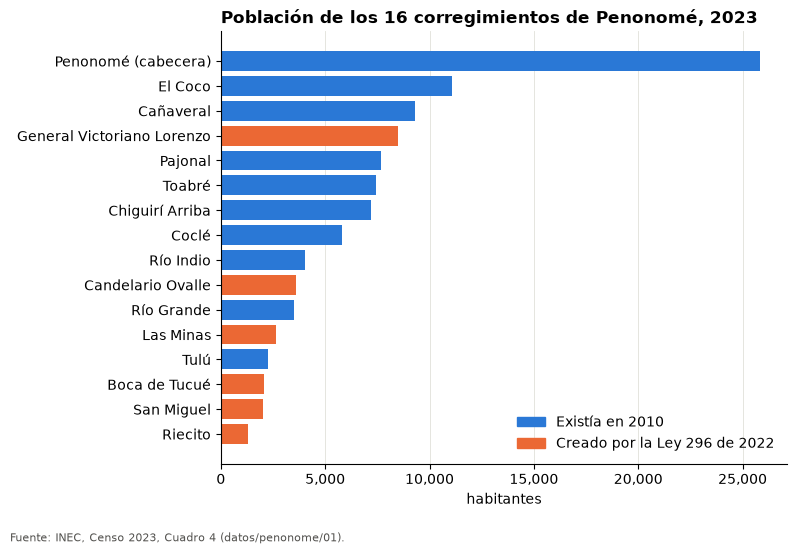

In [8]:
grandes = pob_2023[pob_2023 > 8000].sort_values(ascending=False)
print(grandes)
verificar("corregimientos con más de 8,000 habitantes", len(grandes), 4)

nuevos = set(crecimiento[crecimiento.isna()].index)
ordenada = pob_2023.sort_values()
colores = [an.NARANJA if nombre in nuevos else an.AZUL for nombre in ordenada.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(ordenada.index, ordenada.values, color=colores)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=an.AZUL, label="Existía en 2010"),
                   Patch(color=an.NARANJA, label="Creado por la Ley 296 de 2022")],
          frameon=False, loc="lower right")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
an.estilo_eje(ax, "Población de los 16 corregimientos de Penonomé, 2023", "habitantes", "",
              "INEC, Censo 2023, Cuadro 4 (datos/penonome/01).")
ax.grid(True, axis="x", color="#e1e0d9", linewidth=0.6)
ax.grid(False, axis="y")
plt.show()

**Clave:** una Serie es un arreglo con etiquetas. Las operaciones se alinean por índice y los huecos se vuelven `NaN`, lo que avisa de que un dato no es comparable en lugar de dar un número falso.

**Referencia:** [Unidad 35 — Serie Pandas](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb): creación, selección con `loc` e `iloc`, operaciones aritméticas, estadísticas descriptivas y gráfico de barras.

## 3. DataFrames: afectaciones del sismo y Censo 2023

Un DataFrame es una tabla de columnas que comparten el índice ([Unidad 36](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb)). La tabla de afectaciones de SINAPROC (`datos/analisis/afectaciones_sinaproc_cocle.csv`) trae el resultado de la EDAN en Coclé del 9 de octubre al 15 de noviembre de 2026 y algunas otras afectaciones con corte del COE al 25 de noviembre. Está en formato largo: una fila por dato, con `categoria`, `subcategoria`, `desagregacion` y `valor`.

In [9]:
print(afectaciones.shape, "->", afectaciones["categoria"].unique().tolist())

cobertura = afectaciones[afectaciones["categoria"] == "Cobertura"].set_index("subcategoria")   # filtrado y nuevo índice
print(cobertura[["valor", "unidad", "corte"]])
print()
viviendas_evaluadas = int(cobertura.loc["Viviendas evaluadas", "valor"])
personas_evaluadas = int(cobertura.loc["Personas en las viviendas evaluadas", "valor"])
print(f"Personas por vivienda evaluada: {personas_evaluadas / viviendas_evaluadas:.1f}")
verificar("viviendas evaluadas en Coclé", viviendas_evaluadas, 2531)
verificar("personas en las viviendas evaluadas", personas_evaluadas, 10199)

(40, 10) -> ['Cobertura', 'Viviendas por nivel de daño', 'Edad y sexo', 'Atención especial', 'Atención especial por nivel de daño', 'Otras afectaciones']
                                     valor     unidad       corte
subcategoria                                                     
Viviendas evaluadas                   2531  viviendas  2026-11-15
Personas en las viviendas evaluadas  10199   personas  2026-11-15

Personas por vivienda evaluada: 4.0
Correcto: viviendas evaluadas en Coclé
Correcto: personas en las viviendas evaluadas


En esta tabla `subcategoria` y `desagregacion` significan cosas distintas según la categoría: en «Edad y sexo» son el grupo de edad y el sexo; en «Viviendas por nivel de daño» y «Atención especial por nivel de daño» son el nivel de daño y el grupo vulnerable. Por eso se filtra primero una categoría. Con `pivot` (que se estudia a fondo en la semana 6) cada categoría pasa a una tabla pequeña, se agregan columnas calculadas y se comprueba que las partes sumen el total evaluado.

In [10]:
orden_edad = ["Recién nacidos", "Niñez", "Adolescencia", "Adultos", "Adultos mayores"]
edad_sexo = (afectaciones[afectaciones["categoria"] == "Edad y sexo"]
             .pivot(index="subcategoria", columns="desagregacion", values="valor")
             .loc[orden_edad])
edad_sexo["total"] = edad_sexo["Hombres"] + edad_sexo["Mujeres"]
edad_sexo["pct_del_total"] = (edad_sexo["total"] / edad_sexo["total"].sum() * 100).round(1)
edad_sexo["pct_mujeres"] = (edad_sexo["Mujeres"] / edad_sexo["total"] * 100).round(1)
print(edad_sexo)
print()
print("Niñez y adolescencia:", int(edad_sexo.loc[["Niñez", "Adolescencia"], "total"].sum()), "personas")

verificar("edad y sexo suman las personas en las viviendas evaluadas", int(edad_sexo["total"].sum()), personas_evaluadas)
verificar("hombres evaluados", int(edad_sexo["Hombres"].sum()), 5111)
verificar("mujeres evaluadas", int(edad_sexo["Mujeres"].sum()), 5088)

desagregacion    Hombres  Mujeres  total  pct_del_total  pct_mujeres
subcategoria                                                        
Recién nacidos       172      151    323            3.2         46.7
Niñez               1090      897   1987           19.5         45.1
Adolescencia         455      458    913            9.0         50.2
Adultos             2521     2720   5241           51.4         51.9
Adultos mayores      873      862   1735           17.0         49.7

Niñez y adolescencia: 2900 personas
Correcto: edad y sexo suman las personas en las viviendas evaluadas
Correcto: hombres evaluados
Correcto: mujeres evaluadas


Los niveles de daño de las viviendas y las personas que requieren atención especial (con discapacidad y mujeres embarazadas) permiten una pregunta de vulnerabilidad: ¿esas personas se reparten entre los niveles de daño como se reparten las viviendas, o se concentran en alguno? Se compara el porcentaje de viviendas de cada nivel con el porcentaje de personas de cada grupo que vive en viviendas de ese nivel. `Total` es uno de los cinco niveles de daño que usa SINAPROC, no la suma de la tabla.

In [11]:
niveles = ["Total", "Moderado", "Parcial", "Leve", "Menor"]
viviendas_nivel = (afectaciones[afectaciones["categoria"] == "Viviendas por nivel de daño"]
                   .set_index("subcategoria")["valor"].loc[niveles])
atencion = (afectaciones[afectaciones["categoria"] == "Atención especial por nivel de daño"]
            .pivot(index="subcategoria", columns="desagregacion", values="valor")
            .loc[niveles])

comparacion = pd.DataFrame({
    "viviendas": viviendas_nivel,
    "pct_viviendas": (viviendas_nivel / viviendas_nivel.sum() * 100).round(1),
    "pct_discapacidad": (atencion["Personas con discapacidad"] / atencion["Personas con discapacidad"].sum() * 100).round(1),
    "pct_embarazadas": (atencion["Mujeres embarazadas"] / atencion["Mujeres embarazadas"].sum() * 100).round(1),
})
comparacion.index.name = "nivel_de_daño"
print(comparacion)

discapacidad_total = int(afectaciones.query("subcategoria == 'Personas con discapacidad' and categoria == 'Atención especial'")["valor"].iloc[0])
embarazadas_total = int(afectaciones.query("subcategoria == 'Mujeres embarazadas' and categoria == 'Atención especial'")["valor"].iloc[0])
verificar("los cinco niveles suman las viviendas evaluadas", int(viviendas_nivel.sum()), viviendas_evaluadas)
verificar("personas con discapacidad por nivel suman el total", int(atencion["Personas con discapacidad"].sum()), discapacidad_total)
verificar("mujeres embarazadas por nivel suman el total", int(atencion["Mujeres embarazadas"].sum()), embarazadas_total)
verificar("viviendas con daño total", int(viviendas_nivel["Total"]), 414)

               viviendas  pct_viviendas  pct_discapacidad  pct_embarazadas
nivel_de_daño                                                             
Total                414           16.4              17.9             33.3
Moderado             147            5.8               3.2              9.5
Parcial             1750           69.1              72.9             52.4
Leve                 145            5.7               3.0              4.8
Menor                 75            3.0               3.0              0.0
Correcto: los cinco niveles suman las viviendas evaluadas
Correcto: personas con discapacidad por nivel suman el total
Correcto: mujeres embarazadas por nivel suman el total
Correcto: viviendas con daño total


Las personas con discapacidad se concentran en las viviendas del nivel Parcial (72.9 %), algo más que el peso de ese nivel entre las viviendas (69.1 %), y en el nivel Total viven el 17.9 % de ellas frente al 16.4 % de las viviendas. Las diferencias son pequeñas. Las mujeres embarazadas son solo 21 en toda la tabla: con tan pocos casos, un solo caso mueve varios puntos porcentuales, así que no se sacan conclusiones de ese grupo.

El Censo 2023 (tabla 02) permite bajar al nivel de corregimiento, donde está la vulnerabilidad previa al sismo. Se agregan columnas calculadas, se trae la incidencia de pobreza multidimensional del PNUD (tabla 03) alineando por el nombre del corregimiento, se ordena con `sort_values()` y se comprueba que los corregimientos sumen el total del distrito.

In [12]:
censo = tabla02[tabla02["nivel"] == "corregimiento"].set_index("area")
censo["pct_sin_internet"] = (censo["sin_internet"] / censo["viviendas"] * 100).round(1)
censo["pct_analfabeta"] = (censo["analfabeta"] / censo["pob_10mas"] * 100).round(1)
censo["pct_discapacidad"] = (censo["con_discapacidad"] / censo["poblacion"] * 100).round(1)
ipm = leer("03_pnud_ipm_corregimientos_2023.csv").set_index("corregimiento")
censo["incidencia_ipm"] = ipm["incidencia_h"]          # se alinea por el índice, como en las Series

print(censo[["poblacion", "pct_sin_internet", "pct_analfabeta", "pct_discapacidad", "incidencia_ipm"]]
      .sort_values("incidencia_ipm", ascending=False).head(6))

distrito = tabla02[tabla02["nivel"] == "distrito"].iloc[0]
provincia = tabla02[tabla02["nivel"] == "provincia"].iloc[0]
sumas = censo[["poblacion", "analfabeta", "con_discapacidad"]].sum()
pct_analfabeta_distrito = float(round(distrito["analfabeta"] / distrito["pob_10mas"] * 100, 1))
print()
print("Analfabetismo del distrito:", pct_analfabeta_distrito, "% de la población de 10 años y más")
print(f"Viviendas evaluadas por la EDAN frente al total de viviendas de Coclé: {viviendas_evaluadas / provincia['viviendas'] * 100:.1f} %")

verificar("población de los corregimientos = distrito", int(sumas["poblacion"]), int(distrito["poblacion"]))
verificar("analfabetos de los corregimientos = distrito", int(sumas["analfabeta"]), int(distrito["analfabeta"]))
verificar("personas con discapacidad de los corregimientos = distrito", int(sumas["con_discapacidad"]), int(distrito["con_discapacidad"]))
verificar("los 16 corregimientos tienen incidencia de pobreza", int(censo["incidencia_ipm"].notna().sum()), 16)
verificar("tasa de analfabetismo del distrito (%)", pct_analfabeta_distrito, 1.9)

                   poblacion  pct_sin_internet  pct_analfabeta  \
area                                                             
Riecito                 1315              98.2             4.8   
San Miguel              2038              94.9             4.7   
Río Indio               4026              99.0             2.5   
Tulú                    2241              99.4             5.6   
Candelario Ovalle       3615              78.2             2.0   
Boca de Tucué           2090              98.6             4.6   

                   pct_discapacidad  incidencia_ipm  
area                                                 
Riecito                         2.4              86  
San Miguel                      5.9              81  
Río Indio                       2.1              77  
Tulú                            3.4              76  
Candelario Ovalle               2.8              75  
Boca de Tucué                   3.2              71  

Analfabetismo del distrito: 1.9 % de l

**Error común:** leer la fila `Total` de los niveles de daño (414 viviendas) como el total de viviendas evaluadas. Es un nivel de daño: las 2,531 viviendas evaluadas son la suma de los cinco niveles. Tampoco son todas las viviendas de Coclé: la EDAN solo cubre las visitadas, el 3.3 % de las viviendas que cuenta el Censo 2023 en la provincia del total que cuenta el Censo.

**Clave:** con un DataFrame se filtra (`df[condicion]`), se cambia el índice (`set_index`), se seleccionan celdas (`loc`), se agregan columnas calculadas y se ordena (`sort_values`), siempre sobre la tabla completa y sin bucles. Cuando dos tablas comparten el nombre del corregimiento, asignar una columna de una a la otra alinea por el índice.

**Referencia:** [Unidad 36 — Pandas DataFrame](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb): creación, índice y columnas, lectura de CSV, selección y filtrado.

## 4. Programación dinámica

### 4.1 El tramo de edades con más mujeres que hombres: subarreglo de suma máxima

La práctica en pareja de la [Unidad 32](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u32-programacion-dinamica.ipynb) pide el tramo de valores consecutivos con la suma máxima. Aplicado a la tabla de edad y sexo de la EDAN, para cada grupo de edad (en orden, de recién nacidos a adultos mayores) se calcula `mujeres - hombres`. La pregunta es: **¿cuál es el tramo de grupos de edad consecutivos con la mayor ventaja acumulada de mujeres?** La recurrencia ascendente `mejor_hasta = max(S[i], mejor_hasta + S[i])` lo resuelve en un solo recorrido; `an.maximum_subarray` además devuelve dónde empieza y acaba el tramo. En el [notebook de la semana 4](s04-ordenamiento-greedy-divide-y-venceras.ipynb) el mismo problema se resolvió con dividir y vencerás sobre los intervalos entre cortes de réplicas.

In [13]:
diferencia_edad = edad_sexo["Mujeres"] - edad_sexo["Hombres"]
S = diferencia_edad.tolist()
grupos = diferencia_edad.index.tolist()
print(dict(zip(grupos, S)))

mejor, inicio, fin = an.maximum_subarray(S)
print(f"Mejor tramo: {grupos[inicio]} a {grupos[fin]}, {mejor:+d} mujeres más que hombres")

# Comprobación con fuerza bruta: probar todos los tramos (O(n^2))
fuerza_bruta = max(sum(S[i:j + 1]) for i in range(len(S)) for j in range(i, len(S)))
verificar("la recurrencia coincide con la fuerza bruta", mejor, fuerza_bruta)
verificar("suma del mejor tramo (personas)", mejor, 202)
verificar("grupos del mejor tramo", (grupos[inicio], grupos[fin]), ("Adolescencia", "Adultos"))
verificar("la suma de todos los grupos es negativa: hay más hombres que mujeres", sum(S) < 0, True)

{'Recién nacidos': -21, 'Niñez': -193, 'Adolescencia': 3, 'Adultos': 199, 'Adultos mayores': -11}
Mejor tramo: Adolescencia a Adultos, +202 mujeres más que hombres
Correcto: la recurrencia coincide con la fuerza bruta
Correcto: suma del mejor tramo (personas)
Correcto: grupos del mejor tramo
Correcto: la suma de todos los grupos es negativa: hay más hombres que mujeres


Las mujeres superan a los hombres en adolescencia (+3) y sobre todo en adultos (+199); en recién nacidos (-21), niñez (-193) y adultos mayores (-11) hay más hombres. El tramo de mayor ventaja femenina va de adolescencia a adultos y suma +202.

**Error común:** pensar que el mejor tramo es toda la serie. La suma de los cinco grupos es -23 personas (hay más hombres que mujeres entre las personas evaluadas), pero el tramo de adolescencia a adultos suma 0: la recurrencia empieza un tramo nuevo cuando arrastrar el pasado resta, porque `max(S[i], mejor_hasta + S[i])` descarta el pasado negativo.

### 4.2 Reparto de brigadas: mochila 0/1 con memorización

En la semana 4 el greedy repartía un presupuesto entre corregimientos y no garantizaba el óptimo, porque un corregimiento se atiende completo o no se atiende (mochila 0/1). La programación dinámica sí lo garantiza. El problema de esta sección es parecido: hay un número limitado de brigadas de atención social y se decide a qué corregimientos de Penonomé enviarlas para llegar a la mayor cantidad de personas en pobreza multidimensional.

- **Beneficio (dato):** personas en pobreza multidimensional de cada corregimiento, `poblacion_ipm * incidencia_h / 100` (PNUD, 2023, tabla 03).
- **Costo (supuesto ilustrativo):** una brigada por cada 1,000 personas en pobreza, redondeando hacia arriba.
- **Capacidad (supuesto ilustrativo):** 8 brigadas, y también 13 para comparar.

Estos costos y capacidades no vienen de ninguna fuente oficial: solo sirven para ilustrar el algoritmo. La recurrencia es `mejor(i, cap) = max(mejor(i + 1, cap), valor[i] + mejor(i + 1, cap - costo[i]))`. `an.mochila_01` guarda cada par `(i, cap)` en un diccionario `memo`, como `fib_memo` en la práctica de la u32, y todas las ramas comparten esa tabla.

In [14]:
import math

ipm = leer("03_pnud_ipm_corregimientos_2023.csv")
ipm["pobres"] = (ipm["poblacion_ipm"] * ipm["incidencia_h"] / 100).round().astype(int)       # dato
PERSONAS_POR_BRIGADA = 1_000                                                                 # supuesto ilustrativo
ipm["brigadas"] = (ipm["pobres"] / PERSONAS_POR_BRIGADA).apply(math.ceil)

nombres, valores, costos = ipm["corregimiento"].tolist(), ipm["pobres"].tolist(), ipm["brigadas"].tolist()
print(f"Personas en pobreza en los 16 corregimientos: {sum(valores):,} | brigadas para atenderlos a todos: {sum(costos)}")

CAPACIDAD = 8                                                                                # supuesto ilustrativo
total, elegidos, memo = an.mochila_01(valores, costos, CAPACIDAD)
print(f"\nCon {CAPACIDAD} brigadas:")
for i in elegidos:
    print(f"  {nombres[i]:<28} {valores[i]:>6,} personas en pobreza  {costos[i]} brigadas")
print(f"Total: {total:,} personas con {sum(costos[i] for i in elegidos)} brigadas")

def sin_memo(i, cap, llamadas):
    """La misma recurrencia sin tabla: cuenta cuántas veces se llama a sí misma."""
    llamadas[0] += 1
    if i == len(valores):
        return 0
    sin = sin_memo(i + 1, cap, llamadas)
    con = valores[i] + sin_memo(i + 1, cap - costos[i], llamadas) if costos[i] <= cap else -1
    return max(sin, con)

llamadas = [0]
verificar("sin memorización da el mismo valor", sin_memo(0, CAPACIDAD, llamadas), total)
print(f"Llamadas sin memorización: {llamadas[0]:,} | entradas en la tabla memo: {len(memo):,} | subconjuntos posibles: {2 ** len(valores):,}")
verificar("la memorización calcula menos casos que llamadas hace la recursión simple", len(memo) < llamadas[0], True)
verificar("lo elegido cabe en la capacidad", sum(costos[i] for i in elegidos) <= CAPACIDAD, True)
verificar("el valor elegido es el total", sum(valores[i] for i in elegidos), total)

Personas en pobreza en los 16 corregimientos: 35,852 | brigadas para atenderlos a todos: 44

Con 8 brigadas:
  Penonomé (cabecera)           4,000 personas en pobreza  4 brigadas
  Toabré                        3,495 personas en pobreza  4 brigadas
Total: 7,495 personas con 8 brigadas
Correcto: sin memorización da el mismo valor
Llamadas sin memorización: 2,534 | entradas en la tabla memo: 121 | subconjuntos posibles: 65,536
Correcto: la memorización calcula menos casos que llamadas hace la recursión simple
Correcto: lo elegido cabe en la capacidad
Correcto: el valor elegido es el total


In [15]:
def greedy(capacidad, criterio):
    """Ordena por el criterio (de mayor a menor) y toma cada corregimiento si todavía caben sus brigadas."""
    usado = beneficio = 0
    elegidos = []
    for i in sorted(range(len(valores)), key=lambda i: -criterio(i)):
        if usado + costos[i] <= capacidad:
            usado += costos[i]
            beneficio += valores[i]
            elegidos.append(nombres[i])
    return beneficio, elegidos

def fuerza_bruta(capacidad):
    """Prueba los 2^16 subconjuntos y devuelve el mayor beneficio que cabe."""
    mejor = 0
    for mascara in range(1 << len(valores)):
        costo = beneficio = 0
        for i in range(len(valores)):
            if mascara >> i & 1:
                costo += costos[i]
                beneficio += valores[i]
        if costo <= capacidad and beneficio > mejor:
            mejor = beneficio
    return mejor

resultados = {}
print(f"{'brigadas':>9} {'greedy razón':>13} {'greedy mayor':>13} {'mochila (DP)':>13} {'fuerza bruta':>13}")
for capacidad in (8, 13):
    g_razon, quien_razon = greedy(capacidad, lambda i: valores[i] / costos[i])
    g_mayor, _ = greedy(capacidad, lambda i: valores[i])
    dinamica = an.mochila_01(valores, costos, capacidad)[0]
    resultados[capacidad] = (g_razon, g_mayor, dinamica, fuerza_bruta(capacidad))
    print(f"{capacidad:>9} {g_razon:>13,} {g_mayor:>13,} {dinamica:>13,} {resultados[capacidad][3]:>13,}")
    elegidos_dp = [nombres[i] for i in an.mochila_01(valores, costos, capacidad)[1]]
    print(f"{'':>9} greedy por razón: {', '.join(quien_razon)}")
    print(f"{'':>9} mochila (DP)    : {', '.join(elegidos_dp)}")

verificar("la mochila coincide con la fuerza bruta (8 y 13 brigadas)", all(d == f for _, _, d, f in resultados.values()), True)
verificar("con 8 brigadas el greedy por razón no alcanza el óptimo", resultados[8][0] < resultados[8][2], True)
verificar("con 13 brigadas el greedy por razón tampoco lo alcanza", resultados[13][0] < resultados[13][2], True)
verificar("la mochila nunca queda por debajo de un greedy", all(d >= max(r, m) for r, m, d, _ in resultados.values()), True)

 brigadas  greedy razón  greedy mayor  mochila (DP)  fuerza bruta
        8         7,458         7,298         7,495         7,495
          greedy por razón: Penonomé (cabecera), Candelario Ovalle, Coclé
          mochila (DP)    : Penonomé (cabecera), Toabré
       13        12,053        12,090        12,090        12,090
          greedy por razón: Penonomé (cabecera), Chiguirí Arriba, Candelario Ovalle, Coclé
          mochila (DP)    : Penonomé (cabecera), Chiguirí Arriba, Toabré
Correcto: la mochila coincide con la fuerza bruta (8 y 13 brigadas)
Correcto: con 8 brigadas el greedy por razón no alcanza el óptimo
Correcto: con 13 brigadas el greedy por razón tampoco lo alcanza
Correcto: la mochila nunca queda por debajo de un greedy


**Clave:** la memorización convierte la recursión en una tabla que se llena una vez: con 8 brigadas, la recursión simple hace 2,534 llamadas y la tabla `memo` guarda 121 entradas, frente a los 65,536 subconjuntos de la fuerza bruta. Y, a diferencia del greedy, el resultado es exacto. Con 8 brigadas el greedy por razón elige la cabecera, Candelario Ovalle y Coclé (7,458 personas en pobreza); la mochila cambia los dos últimos por Toabré y llega a 7,495. La diferencia es pequeña, pero el greedy no puede reconsiderar una decisión ya tomada y la mochila sí compara todas las combinaciones que caben.

**Error común:** leer este reparto como una recomendación de política. Solo el número de personas en pobreza sale de los datos (PNUD, 2023); el costo en brigadas y la capacidad son supuestos ilustrativos, y la pobreza multidimensional mide carencias previas al sismo, no daños.

**Referencia:** [Unidad 32 — Programación dinámica](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u32-programacion-dinamica.ipynb): memorización con diccionario (`fib2`, `fib_memo`) y subarreglo de suma máxima.

## 5. Retroceso: combinaciones de corregimientos

La cabecera tiene 25,836 habitantes. **¿Cuál es el menor número de corregimientos rurales que, juntos, reúnen al menos esa población, y cuáles son todas esas combinaciones?** Probar todos los subconjuntos de los otros 15 corregimientos son 2^15 = 32,768 casos. El retroceso de la [Unidad 33](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb) recorre el árbol de decisiones (incluir o no cada corregimiento) en profundidad y **poda** las ramas no prometedoras:

- si la suma actual más todo lo que queda por elegir no alcanza el objetivo;
- si la rama ya necesitaría más corregimientos que la mejor solución encontrada.

La función `promising` dentro de `an.combinaciones_minimas` cumple el mismo papel que en el problema de las N reinas.

In [16]:
import itertools

rurales = tabla01.drop("penonome_cabecera")
valores = rurales["pob_2023"].tolist()
objetivo = int(tabla01.loc["penonome_cabecera", "pob_2023"])

soluciones, nodos = an.combinaciones_minimas(valores, objetivo)
k = len(soluciones[0])
print(f"Objetivo: {objetivo:,} habitantes. Mínimo de corregimientos: {k}. Combinaciones: {len(soluciones)}")
print(f"Nodos visitados con poda: {nodos:,} de {2 ** len(valores):,} subconjuntos posibles")
print()
for combinacion in soluciones:
    nombres = [rurales["corregimiento"].iloc[i] for i in combinacion]
    print(f"{sum(valores[i] for i in combinacion):>6,}  " + ", ".join(nombres))

Objetivo: 25,836 habitantes. Mínimo de corregimientos: 3. Combinaciones: 10
Nodos visitados con poda: 335 de 32,768 subconjuntos posibles

26,199  Cañaveral, Coclé, El Coco
27,573  Cañaveral, Chiguirí Arriba, El Coco
28,066  Cañaveral, El Coco, Pajonal
27,828  Cañaveral, El Coco, Toabré
28,884  Cañaveral, El Coco, General Victoriano Lorenzo
25,927  Chiguirí Arriba, El Coco, Pajonal
26,745  Chiguirí Arriba, El Coco, General Victoriano Lorenzo
26,182  El Coco, Pajonal, Toabré
27,238  El Coco, Pajonal, General Victoriano Lorenzo
27,000  El Coco, Toabré, General Victoriano Lorenzo


In [17]:
# Comprobación por fuerza bruta con itertools: ninguna combinación de k - 1 llega y las de k coinciden
alcanza = lambda c: sum(valores[i] for i in c) >= objetivo
con_k = sorted(c for c in itertools.combinations(range(len(valores)), k) if alcanza(c))
con_menos = [c for c in itertools.combinations(range(len(valores)), k - 1) if alcanza(c)]

verificar("mínimo de corregimientos para igualar a la cabecera", k, 3)
verificar("número de combinaciones mínimas", len(soluciones), 10)
verificar("el retroceso encuentra las mismas combinaciones que la fuerza bruta", soluciones, con_k)
verificar("ninguna combinación de 2 corregimientos alcanza", con_menos, [])

Correcto: mínimo de corregimientos para igualar a la cabecera
Correcto: número de combinaciones mínimas
Correcto: el retroceso encuentra las mismas combinaciones que la fuerza bruta
Correcto: ninguna combinación de 2 corregimientos alcanza


Basta con tres corregimientos, y las diez combinaciones incluyen siempre a El Coco (11,064), el mayor de los rurales. La poda reduce la búsqueda a 335 nodos: ordenar los valores de mayor a menor hace que la primera solución aparezca pronto, y a partir de ahí el límite de tamaño corta casi todo el árbol.

**Error común:** guardar la lista `elegidos` sin copiarla. Como en `soluciones_n_reinas` de la u33, la lista se sigue modificando al retroceder; por eso la función guarda `tuple(sorted(elegidos))`.

**Referencia:** [Unidad 33 — Retroceso](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb): búsqueda en profundidad, función `promising`, poda y subconjuntos con suma objetivo.

## Conclusiones

- Módulos (u34): el código del proyecto quedó en un paquete con un módulo por etapa; los notebooks importan `penonome.analisis` y no repiten funciones. Con `datetime` se fechan el sismo (9 de octubre de 2026) y los dos cortes de SINAPROC, a 37 y 47 días.
- Series (u35): la población de Penonomé está muy concentrada (la cabecera es el 24.8 % del distrito) y la alineación por índice deja en `NaN` a los seis corregimientos nuevos, que no son comparables con 2010.
- DataFrames (u36): la EDAN de SINAPROC evaluó 2,531 viviendas y 10,199 personas en Coclé, y sus partes (edad y sexo, niveles de daño, atención especial) suman esos totales; los totales del Censo por corregimiento suman los del distrito. Los corregimientos con más pobreza multidimensional, como Riecito (86 %) y San Miguel (81 %), tienen entre 78 % y 99 % de viviendas sin internet.
- Programación dinámica (u32): el mejor tramo de la tabla de edad y sexo va de adolescencia a adultos (+202 mujeres más que hombres) y la mochila 0/1 memorizada reparte 8 brigadas entre corregimientos para llegar a 7,495 personas en pobreza, más que el greedy (7,458) y lo mismo que la fuerza bruta; el costo y la capacidad son supuestos ilustrativos.
- Retroceso (u33): con poda, la búsqueda visita 335 nodos en lugar de 32,768 subconjuntos y halla las 10 combinaciones de tres corregimientos que igualan a la cabecera.

La semana 6 reorganiza estos datos en formato ordenado, los convierte en series temporales y cierra el proyecto con el análisis final.

[Proyecto](../../README.md) | [Anterior](s04-ordenamiento-greedy-divide-y-venceras.ipynb) | [Siguiente](s06-ordenacion-series-temporales.ipynb)